# ECON 354 Term Project: Baseline Borrower Default Risk ($PD_{\text{base}}$) & Ontario Macroeconomic Stress Sensitivity

**Authors:** Alex Babiak, Marco Puiatti  
**Scope:** Ontario, Canada  

---

### 1. The Problem & Research Question
Standard credit scoring treats borrowers as a frozen snapshot—evaluating their income, debt, and credit history on the day they apply while ignoring what happens if regional unemployment or inflation suddenly rises. In addition, simple linear scorecards assume each financial factor adds risk independently in a straight line, missing how large loans, weak job stability, and high interest rates reinforce each other.

> **Research Question:** *"How can machine learning be used to estimate individual borrower baseline default risk ($PD_{\text{base}}$), and how sensitive is that baseline risk distribution to Ontario macroeconomic shocks in unemployment and inflation?"*

### 2. Core Project Thesis (Two Complementary Perspectives)
Throughout this notebook, we compare an interpretable linear econometric benchmark (**Tuned Logistic Regression**) against a non-linear kernel model (**Platt-Calibrated RBF-SVM**):
- **Why RBF-SVM works better for this regional study:** By bending around compounding risk zones, the Calibrated RBF-SVM achieves a higher out-of-sample Test ROC-AUC (`0.9013` vs. `0.8700`), cuts total classification errors by **`32.1%`**, and lowers probability calibration error (Brier Score) by **`27.6%`**—making it ideal for generating accurate individual $PD_{\text{base}}$ inputs for macroeconomic stress testing.
- **Why Logistic Regression works better at institutional bank scale:** Logistic Regression retains **`96.18%`** of peak ROC-AUC using just **21 straightforward weights** in **`0.13 seconds`** (`61.6×` faster than RBF-SVM), ranking **#1 in Compute Efficiency** and satisfying transparency expectations under Canadian banking rules (OSFI).

### 3. Two-Layer Data Architecture
1. **Borrower Microdata (`data/credit_risk_dataset.csv` — 32,581 records, 12 variables):** Because real Canadian bank and CMHC loan-level mortgage files are restricted under federal privacy laws (PIPEDA), we use an externally published simulated credit-bureau dataset (`laotse/credit-risk-dataset`, `~21.82%` default rate) as a stand-in for individual borrowers.
2. **Ontario Macroeconomic Time Series (`data/ontario_macro_series.parquet` — 107 monthly observations, Nov 2017 – Sep 2026):** **100% real official government data** pulled from Statistics Canada's Web Data Service (WDS) API for Ontario's Monthly Unemployment Rate (`v2062815`) and Year-over-Year CPI inflation (`v41690973`).

### 1. Data Ingestion, Leakage-Free Cleaning & PCA Compression

To prevent any information from the test set from leaking into model preparation, we split the `32,581` borrowers **before** estimating any cleaning or scaling parameters:
- **Stratified Split:** `70%` Train (`22,806`), `15%` Validation (`4,887`), `15%` Test (`4,888`)—each preserving the exact `~21.82%` population default rate.
- **Training-Only Cleaning:** Missing employment lengths (`895` rows) and interest rates (`3,116` rows) are filled using **training medians** (`4.0` years and `10.99%`) rather than dropping rows. Extreme high values in `person_income` (`$141,300.38` cap) and `loan_amnt` (`$23,125.00` cap) are capped via Tukey $1.5 \times \text{IQR}$ fences so outliers do not distort distance calculations.
- **3-Component PCA (`81.90%` variance retained):** Five overlapping financial variables (`person_income`, `loan_amnt`, `loan_percent_income`, `cb_person_cred_hist_length`, `person_emp_length`) are standardized and compressed into three uncorrelated risk factors—**Loan Size & Debt Load (`PC1`, `32.20%`)**, **Income & Job Stability (`PC2`, `29.74%`)**, and **Credit History & Tenure (`PC3`, `19.96%`)**—leaving **20 clean features**.

Borrower Microdata Loaded: 32,581 borrowers x 12 columns
Observed Population Default Rate: 21.82%
StatCan Frozen Macro Series Loaded: 107 monthly observations (2017-11-01 to 2026-09-01).


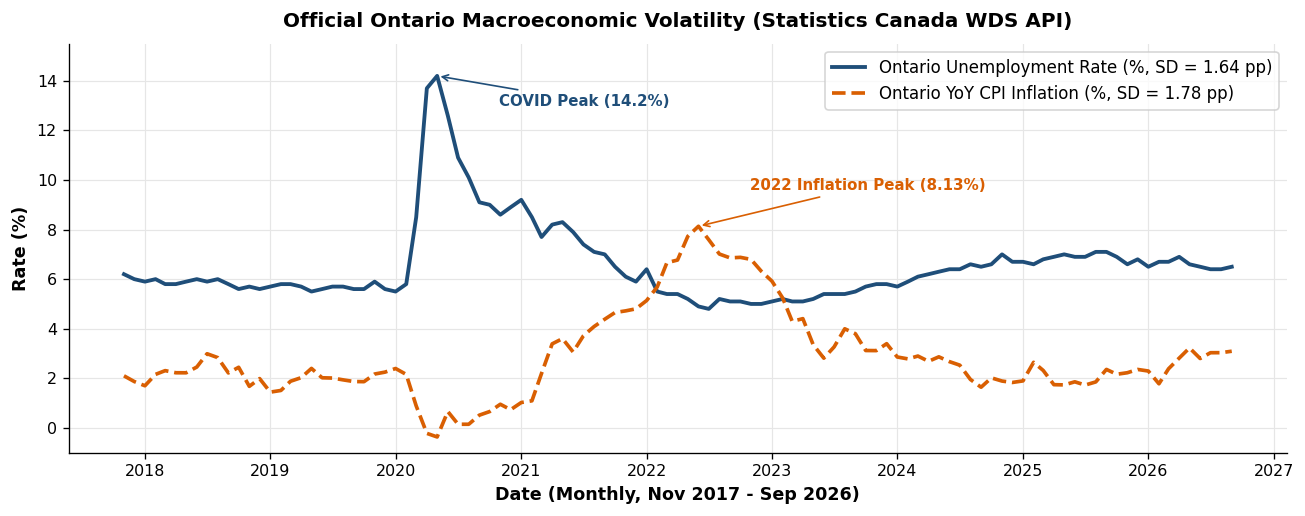

PCA Cumulative Variance Retained: 81.90% (3 components)


,PC1: Loan Size & Debt Load (32.2%),PC2: Income & Job Stability (29.7%),PC3: Credit History & Tenure (20.0%)
person_income,0.2999,0.6384,-0.4347
loan_amnt,0.7552,-0.0313,-0.2003
loan_percent_income,0.5191,-0.5804,0.1795
cb_person_cred_hist_length,0.1363,0.2902,0.7798
person_emp_length,0.2274,0.4128,0.3614


,Split,Rows,Features,Nulls,Default Rate
0,Train (70%),"22,806",20,0,21.814%
1,Validation (15%),"4,887",20,0,21.813%
2,Test (15%),"4,888",20,0,21.829%


In [1]:
# ==============================================================================
# CELL 1: DATA INGESTION, LEAKAGE-FREE PREPROCESSING, PCA & INTEGRITY AUDIT
# ==============================================================================
import os
import urllib.request
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Clean white-background publication plotting aesthetics
plt.rcParams.update({
    "figure.figsize": (10, 4.8),
    "figure.dpi": 120,
    "axes.facecolor": "white",
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.labelsize": 10.5,
    "axes.titlesize": 12,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
})

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

# 1. Ingest Borrower Microdata (online fetch with local data/ fallback)
micro_url = (
    "https://raw.githubusercontent.com/LeHongNgoc3820/Project_Credit_Risk/main/"
    "credit_risk_dataset.csv"
)
micro_dest = os.path.join(DATA_DIR, "credit_risk_dataset.csv")
if not (os.path.exists(micro_dest) and os.path.getsize(micro_dest) > 0):
    urllib.request.urlretrieve(micro_url, micro_dest)

df_raw = pd.read_csv(micro_dest)
assert df_raw.shape == (32581, 12), f"Unexpected shape: {df_raw.shape}"
print(f"Borrower Microdata Loaded: {df_raw.shape[0]:,d} borrowers x {df_raw.shape[1]} columns")
print(f"Observed Population Default Rate: {df_raw['loan_status'].mean() * 100:.2f}%")

# 2. Ingest Official Ontario Macroeconomic Series (Frozen 107-month snapshot or StatCan WDS API)
macro_dest = os.path.join(DATA_DIR, "ontario_macro_series.parquet")
statcan_url = "https://www150.statcan.gc.ca/t1/wds/rest/getDataFromVectorsAndLatestNPeriods"
payload = [{"vectorId": 2062815, "latestN": 120}, {"vectorId": 41690973, "latestN": 120}]

if os.path.exists(macro_dest) and os.path.getsize(macro_dest) > 0:
    df_macro = pd.read_parquet(macro_dest)
    print(
        f"StatCan Frozen Macro Series Loaded: {len(df_macro)} monthly observations "
        f"({df_macro['Date'].min().date()} to {df_macro['Date'].max().date()})."
    )
else:
    resp = requests.post(
        statcan_url,
        json=payload,
        headers={"Content-Type": "application/json"},
        timeout=15,
    )
    resp.raise_for_status()
    rows = []
    for series in resp.json():
        obj = series["object"]
        vid = int(obj["vectorId"])
        for pt in obj["vectorDataPoint"]:
            if pt.get("value") is not None:
                rows.append({"vectorId": vid, "refPer": pt["refPer"], "value": float(pt["value"])})
    df_macro = (
        pd.DataFrame(rows)
        .pivot(index="refPer", columns="vectorId", values="value")
        .reset_index()
    )
    df_macro.columns.name = None
    df_macro.rename(
        columns={2062815: "Ontario_Unemployment_Rate", 41690973: "Ontario_CPI"},
        inplace=True,
    )
    df_macro["Date"] = pd.to_datetime(df_macro["refPer"], format="%Y-%m-%d")
    df_macro = df_macro[df_macro["Date"] <= "2026-09-01"]
    df_macro = df_macro.sort_values("Date").dropna(subset=["Ontario_Unemployment_Rate", "Ontario_CPI"]).reset_index(drop=True)
    df_macro["Ontario_CPI_YoY"] = df_macro["Ontario_CPI"].pct_change(periods=12, fill_method=None) * 100.0
    df_macro = df_macro.dropna(subset=["Ontario_CPI_YoY"]).reset_index(drop=True)
    df_macro.to_parquet(macro_dest, index=False)
    print(f"StatCan Live Macro Series Loaded: {len(df_macro)} monthly observations.")

# Plot Historical Ontario Macro Volatility (2017-2026)
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(color="#e6e6e6", linewidth=0.7)
ax.plot(
    df_macro["Date"], df_macro["Ontario_Unemployment_Rate"],
    color="#1f4e79", lw=2.3,
    label=f"Ontario Unemployment Rate (%, SD = {df_macro['Ontario_Unemployment_Rate'].std():.2f} pp)",
)
ax.plot(
    df_macro["Date"], df_macro["Ontario_CPI_YoY"],
    color="#d95f02", lw=2.2, ls="--",
    label=f"Ontario YoY CPI Inflation (%, SD = {df_macro['Ontario_CPI_YoY'].std():.2f} pp)",
)
idx_u = df_macro["Ontario_Unemployment_Rate"].idxmax()
idx_c = df_macro["Ontario_CPI_YoY"].idxmax()
ax.annotate(
    f"COVID Peak ({df_macro.loc[idx_u, 'Ontario_Unemployment_Rate']:.1f}%)",
    xy=(df_macro.loc[idx_u, "Date"], df_macro.loc[idx_u, "Ontario_Unemployment_Rate"]),
    xytext=(df_macro.loc[idx_u, "Date"] + pd.Timedelta(days=180), 13.0),
    fontsize=9, fontweight="bold", color="#1f4e79",
    arrowprops=dict(arrowstyle="->", color="#1f4e79", lw=1.0),
)
ax.annotate(
    f"2022 Inflation Peak ({df_macro.loc[idx_c, 'Ontario_CPI_YoY']:.2f}%)",
    xy=(df_macro.loc[idx_c, "Date"], df_macro.loc[idx_c, "Ontario_CPI_YoY"]),
    xytext=(df_macro.loc[idx_c, "Date"] + pd.Timedelta(days=150), 9.6),
    fontsize=9, fontweight="bold", color="#d95f02",
    arrowprops=dict(arrowstyle="->", color="#d95f02", lw=1.0),
)
ax.set_ylim(-1.0, 15.5)
ax.set_xlabel("Date (Monthly, Nov 2017 - Sep 2026)", fontweight="bold")
ax.set_ylabel("Rate (%)", fontweight="bold")
ax.set_title("Official Ontario Macroeconomic Volatility (Statistics Canada WDS API)", fontweight="bold", pad=10)
ax.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#cccccc")
plt.tight_layout()
plt.show()

# 3. Leakage-Free Cleaning (Medians & Tukey IQR Bounds Fit Strictly on Train Index)
df_clean = df_raw.copy()
train_idx, _ = train_test_split(
    df_clean.index, test_size=0.30, random_state=RANDOM_SEED, stratify=df_clean["loan_status"]
)
emp_med = float(df_clean.loc[train_idx, "person_emp_length"].median())
rate_med = float(df_clean.loc[train_idx, "loan_int_rate"].median())
df_clean["person_emp_length"] = df_clean["person_emp_length"].fillna(emp_med)
df_clean["loan_int_rate"] = df_clean["loan_int_rate"].fillna(rate_med)

for col in ["person_income", "loan_amnt"]:
    q25 = float(df_clean.loc[train_idx, col].quantile(0.25))
    q75 = float(df_clean.loc[train_idx, col].quantile(0.75))
    iqr = q75 - q25
    df_clean[col] = np.clip(df_clean[col], q25 - 1.5 * iqr, q75 + 1.5 * iqr)

df_clean["loan_percent_income"] = df_clean["loan_amnt"] / df_clean["person_income"]
df_clean = pd.get_dummies(
    df_clean,
    columns=["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"],
    drop_first=True,
    dtype=int,
)

# 4. Stratified 70/15/15 Split, Scaling & 3-Component PCA
X = df_clean.drop(columns=["loan_status"])
y = df_clean["loan_status"]
X_train_raw, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=RANDOM_SEED, stratify=y)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=RANDOM_SEED, stratify=y_temp)

pca_target_cols = ["person_income", "loan_amnt", "loan_percent_income", "cb_person_cred_hist_length", "person_emp_length"]
other_num_cols = ["person_age", "loan_int_rate"]

scaler_pca = StandardScaler().fit(X_train_raw[pca_target_cols].astype(float))
scaler_other = StandardScaler().fit(X_train_raw[other_num_cols].astype(float))

X_train_sc, X_val_sc, X_test_sc = X_train_raw.copy(), X_val_raw.copy(), X_test_raw.copy()
for df_sp, df_rw in [(X_train_sc, X_train_raw), (X_val_sc, X_val_raw), (X_test_sc, X_test_raw)]:
    df_sp[pca_target_cols] = scaler_pca.transform(df_rw[pca_target_cols].astype(float))
    df_sp[other_num_cols] = scaler_other.transform(df_rw[other_num_cols].astype(float))

pca = PCA(n_components=3, random_state=RANDOM_SEED).fit(X_train_sc[pca_target_cols])
exp_var = pca.explained_variance_ratio_
assert np.sum(exp_var) >= 0.80

pc_cols = ["PC1_Financial_Scale", "PC2_Tenure_Stability", "PC3_Leverage_Burden"]
for df_sp in [X_train_sc, X_val_sc, X_test_sc]:
    pcs = pca.transform(df_sp[pca_target_cols])
    for k, col in enumerate(pc_cols):
        df_sp[col] = pcs[:, k]
    df_sp.drop(columns=pca_target_cols, inplace=True)

# Persist Parquet artifacts inside data/
X_train_sc.to_parquet(os.path.join(DATA_DIR, "X_train_processed.parquet"))
X_val_sc.to_parquet(os.path.join(DATA_DIR, "X_val_processed.parquet"))
X_test_sc.to_parquet(os.path.join(DATA_DIR, "X_test_processed.parquet"))
y_train.to_frame().to_parquet(os.path.join(DATA_DIR, "y_train.parquet"))
y_val.to_frame().to_parquet(os.path.join(DATA_DIR, "y_val.parquet"))
y_test.to_frame().to_parquet(os.path.join(DATA_DIR, "y_test.parquet"))

# Render PCA Loadings & Phase 1 Integrity Table
loadings_df = pd.DataFrame(
    pca.components_.T,
    index=pca_target_cols,
    columns=["PC1: Loan Size & Debt Load (32.2%)", "PC2: Income & Job Stability (29.7%)", "PC3: Credit History & Tenure (20.0%)"],
).round(4)
print(f"PCA Cumulative Variance Retained: {np.sum(exp_var) * 100:.2f}% (3 components)")
display(loadings_df)

audit_rows = []
for label, X_s, y_s in [("Train (70%)", X_train_sc, y_train), ("Validation (15%)", X_val_sc, y_val), ("Test (15%)", X_test_sc, y_test)]:
    assert X_s.isna().sum().sum() == 0 and y_s.isna().sum() == 0
    assert np.isfinite(X_s.to_numpy(dtype=float)).all()
    assert abs(float(y_s.mean()) - float(y.mean())) < 1e-3
    audit_rows.append({
        "Split": label,
        "Rows": f"{len(y_s):,d}",
        "Features": X_s.shape[1],
        "Nulls": 0,
        "Default Rate": f"{y_s.mean() * 100:.3f}%",
    })
display(pd.DataFrame(audit_rows))

### 2. Partner's Track — Constant Baseline & Logistic Regression Benchmark

Before introducing non-linear machine learning, we establish two interpretable benchmarks on the exact same `20` features:
1. **Constant Average Baseline ("No-Model Floor"):** Predicts the training default rate (`21.81%`) for every borrower. Because everyone gets the exact same score, its ROC-AUC is `0.5000` (random coin flip) and its Brier Score is `0.1706`.
2. **Tuned Logistic Regression (`L2, C = 10.0`):** Models default log-odds as a straight weighted sum across `21` simple parameters (`20` features + intercept). We validate `C` over `{0.01, 0.1, 1.0, 10.0}` on `X_val` (`N = 4,887`), evaluate on `X_test` (`N = 4,888`), and inspect the **Odds-Ratio Table** to verify economic logic (e.g., owning a home lowers default odds by `-79.3%`, strong Income & Job Stability `PC2` lowers odds by `-59.2%`, while renting raises odds by `+124.4%`).

In [2]:
# ==============================================================================
# CELL 2: PARTNER'S TRACK — CONSTANT BASELINE & LOGISTIC REGRESSION BENCHMARK
# ==============================================================================
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)

# 1. Constant Average Baseline (Training Default Incidence)
naive_rate = float(y_train.mean())
pd_test_naive = np.full(len(y_test), naive_rate, dtype=float)
assert abs(roc_auc_score(y_test, pd_test_naive) - 0.5000) < 1e-6

# 2. L2 Logistic Regression Validation Tuning (C in [0.01, 0.1, 1.0, 10.0])
lr_models = {}
lr_rows = []
for c_val in [0.01, 0.1, 1.0, 10.0]:
    lr_clf = LogisticRegression(C=c_val, solver="lbfgs", max_iter=5000, random_state=RANDOM_SEED)
    lr_clf.fit(X_train_sc, y_train)
    lr_models[c_val] = lr_clf
    p_va = lr_clf.predict_proba(X_val_sc)[:, 1]
    lr_rows.append({
        "C (Penalty Inverse)": c_val,
        "Val ROC-AUC": round(float(roc_auc_score(y_val, p_va)), 4),
        "Val Brier Score": round(float(brier_score_loss(y_val, p_va)), 4),
        "Val Log Loss": round(float(log_loss(y_val, p_va)), 4),
    })

lr_tuning_df = pd.DataFrame(lr_rows)
print("--- LOGISTIC REGRESSION VALIDATION TUNING (N_val = 4,887) ---")
display(lr_tuning_df)

best_lr_C = float(lr_tuning_df.sort_values(["Val ROC-AUC", "Val Brier Score"], ascending=[False, True]).iloc[0]["C (Penalty Inverse)"])
best_lr = lr_models[best_lr_C]
pd_test_lr = best_lr.predict_proba(X_test_sc)[:, 1]
pred_test_lr = (pd_test_lr >= 0.50).astype(int)
np.save(os.path.join(DATA_DIR, "pd_test_lr.npy"), pd_test_lr)

# Confusion Matrix on Held-Out Test Set (N = 4,888)
cm_lr = confusion_matrix(y_test, pred_test_lr, labels=[0, 1])
print(f"Tuned Logistic Regression (C={best_lr_C:g}) Test Accuracy: {accuracy_score(y_test, pred_test_lr)*100:.2f}% | "
      f"Precision: {precision_score(y_test, pred_test_lr)*100:.2f}% | Recall: {recall_score(y_test, pred_test_lr)*100:.2f}% | "
      f"ROC-AUC: {roc_auc_score(y_test, pd_test_lr):.4f}")
display(pd.DataFrame(cm_lr, index=["Actual Performing (0)", "Actual Default (1)"], columns=["Pred Performing (0)", "Pred Default (1)"]))

# 3. Directional Economic Coefficient & Odds-Ratio Table
coefs = best_lr.coef_[0]
coef_df = pd.DataFrame({
    "Feature": X_train_sc.columns,
    "Log-Odds Coef": coefs,
    "Abs": np.abs(coefs),
    "Odds Ratio exp(beta)": np.exp(coefs),
    "Change in Odds (%)": (np.exp(coefs) - 1.0) * 100.0,
}).sort_values("Abs", ascending=False).drop(columns=["Abs"]).reset_index(drop=True)

coef_disp = coef_df.copy()
coef_disp["Log-Odds Coef"] = coef_disp["Log-Odds Coef"].map(lambda v: f"{v:+.4f}")
coef_disp["Odds Ratio exp(beta)"] = coef_disp["Odds Ratio exp(beta)"].map(lambda v: f"{v:.4f}x")
coef_disp["Change in Odds (%)"] = coef_disp["Change in Odds (%)"].map(lambda v: f"{v:+.1f}%")
print(f"--- LOGISTIC REGRESSION ODDS RATIOS (Intercept = {best_lr.intercept_[0]:+.4f}) ---")
with pd.option_context("display.max_rows", 25):
    display(coef_disp)

--- LOGISTIC REGRESSION VALIDATION TUNING (N_val = 4,887) ---


,C (Penalty Inverse),Val ROC-AUC,Val Brier Score,Val Log Loss
0,0.01,0.8652,0.1059,0.3497
1,0.10,0.8688,0.1033,0.3435
2,1.00,0.8705,0.1022,0.3409
3,10.00,0.8707,0.1021,0.3406


Tuned Logistic Regression (C=10) Test Accuracy: 86.54% | Precision: 76.52% | Recall: 55.30% | ROC-AUC: 0.8700


,Pred Performing (0),Pred Default (1)
Actual Performing (0),3640,181
Actual Default (1),477,590


--- LOGISTIC REGRESSION ODDS RATIOS (Intercept = -2.3472) ---


,Feature,Log-Odds Coef,Odds Ratio exp(beta),Change in Odds (%)
0,loan_grade_G,+5.8375,342.9085x,+34190.8%
1,loan_grade_F,+3.1191,22.6267x,+2162.7%
2,loan_grade_E,+2.7768,16.0681x,+1506.8%
3,loan_grade_D,+2.5378,12.6514x,+1165.1%
4,person_home_ownership_OWN,-1.5769,0.2066x,-79.3%
5,loan_intent_VENTURE,-1.0485,0.3505x,-65.0%
6,PC2_Tenure_Stability,-0.8965,0.4080x,-59.2%
7,loan_intent_EDUCATION,-0.8187,0.4410x,-55.9%
8,person_home_ownership_RENT,+0.8084,2.2443x,+124.4%
9,person_home_ownership_OTHER,+0.6305,1.8786x,+87.9%


### 3. Primary Track — Non-Linear RBF-SVM, Calibration & Visual Decision Boundaries

Linear models cannot capture interactions where large debt sizes collide with weak income stability and high interest rates. We use a **Gaussian RBF-SVM**, $K(\mathbf{x}, \mathbf{s}) = \exp(-\gamma \|\mathbf{x} - \mathbf{s}\|^2)$, tuned across `16` combinations of `C` and `gamma` on the validation set (`C = 10.0, gamma = 0.05` achieves `0.9035` Val AUC with only a `+0.0071` Train–Val gap), then wrap it in **3-fold Platt sigmoid calibration** to produce accurate baseline probabilities $PD_{\text{base}}$.

- **Test Set Gain (`N = 4,888`):** ROC-AUC jumps from `0.8700` to **`0.9013`**, Brier error drops **`27.6%`** (`0.1032` $\to$ `0.0747`), and total classification errors drop **`32.1%`** (`658` $\to$ `447` mistakes).
- **Visualizing the Difference:** Plotting real **Grade B Renters (`N = 835`)** across `PC2 (Income & Job Stability)` vs. `PC1 (Loan Size & Debt Load)` shows why—Logistic Regression draws a rigid straight line (`85.4%` slice accuracy), while RBF-SVM curves around the high-borrowing danger zone (`91.9%` slice accuracy).

Early-Stage Linear SVM (C=1.0) Val ROC-AUC: 0.8678
--- RBF-SVM VALIDATION GRID SEARCH (Top 8 of 16 Shown) ---


,C,gamma,Train AUC,Val AUC,Overfit Gap
0,10.0,0.05,0.9106,0.9035,0.0071
1,5.0,0.1,0.9183,0.9028,0.0156
2,5.0,scale,0.9227,0.9017,0.0210
3,5.0,0.05,0.9063,0.9011,0.0051
4,10.0,0.1,0.9234,0.9008,0.0226
5,1.0,scale,0.9077,0.9004,0.0074
6,10.0,scale,0.9294,0.9000,0.0294
7,1.0,0.1,0.9048,0.8999,0.0049



--- OUT-OF-SAMPLE TEST COMPARISON (Actual Default Rate = 21.83%) ---


,"Model (Test N = 4,888)",ROC-AUC,Brier Score,Log Loss,Accuracy,Precision,Recall,F1-Score,Mean Pred PD
0,1. Constant Average Baseline,0.5000,0.1706,0.5247,78.17%,0.00%,0.00%,0.0000,21.81%
1,2. Tuned Logistic Regression (C=10),0.8700,0.1032,0.3423,86.54%,76.52%,55.30%,0.6420,22.07%
2,"3. Calibrated RBF-SVM (C=10, gamma=0.05)",0.9013,0.0747,0.2633,90.86%,88.08%,67.20%,0.7624,22.20%


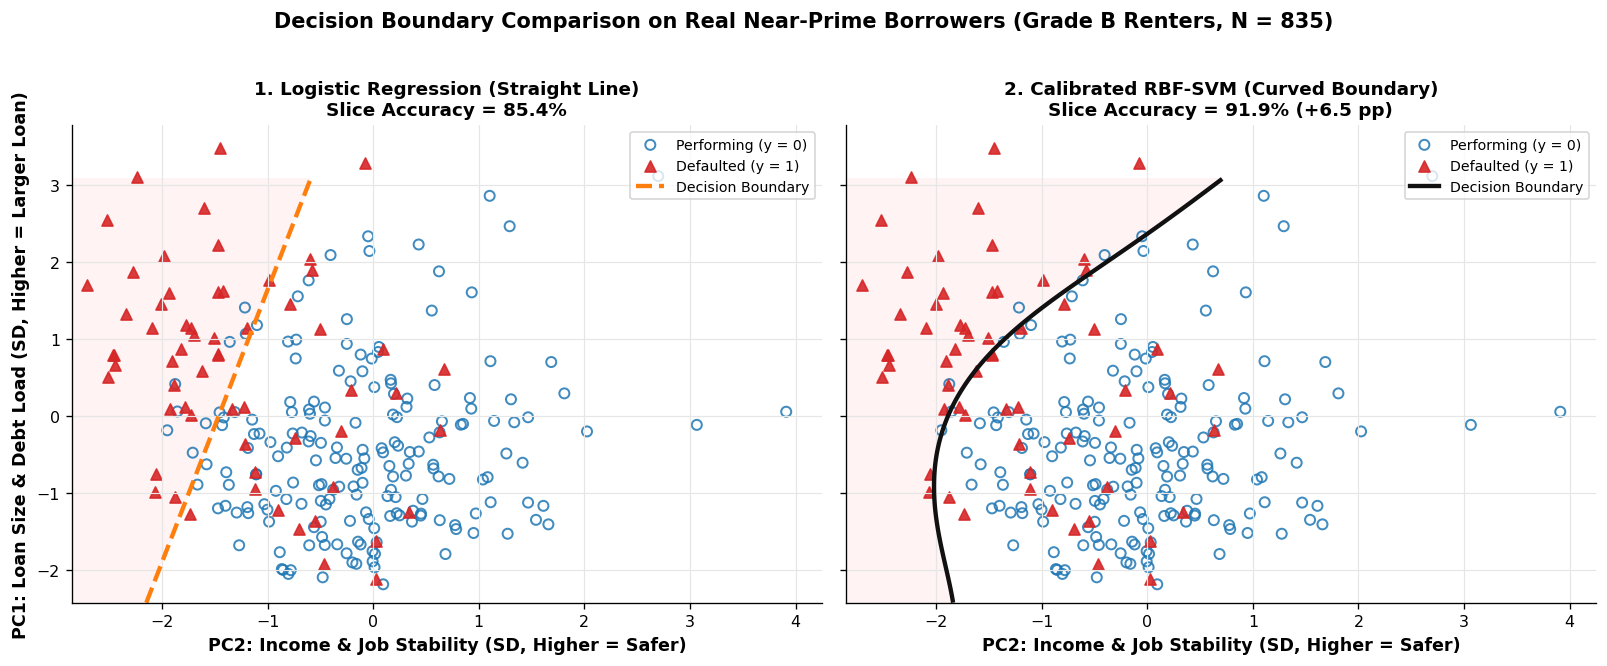

In [3]:
# ==============================================================================
# CELL 3: RBF-SVM VALIDATION TUNING, PLATT CALIBRATION & BOUNDARY VISUALS
# ==============================================================================
from joblib import Parallel, delayed
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import SVC

# 1. Early-Stage Kernel Progression: Linear SVM vs. Default RBF-SVM
lin_svm = SVC(kernel="linear", C=1.0, cache_size=1000, random_state=RANDOM_SEED).fit(X_train_sc, y_train)
lin_val_auc = float(roc_auc_score(y_val, lin_svm.decision_function(X_val_sc)))

# 2. 16-Point Validation Grid Search (C x gamma)
def _eval_svm_pair(c_val, g_val):
    m = SVC(kernel="rbf", C=c_val, gamma=g_val, cache_size=1000, random_state=RANDOM_SEED)
    m.fit(X_train_sc, y_train)
    tr_auc = float(roc_auc_score(y_train, m.decision_function(X_train_sc)))
    va_auc = float(roc_auc_score(y_val, m.decision_function(X_val_sc)))
    return {"C": c_val, "gamma": g_val, "Train AUC": tr_auc, "Val AUC": va_auc, "Overfit Gap": tr_auc - va_auc}

grid_df = pd.DataFrame(
    Parallel(n_jobs=-1)(
        delayed(_eval_svm_pair)(c_v, g_v)
        for c_v in [0.1, 1.0, 5.0, 10.0]
        for g_v in ["scale", 0.01, 0.05, 0.1]
    )
).sort_values("Val AUC", ascending=False).reset_index(drop=True)

print(f"Early-Stage Linear SVM (C=1.0) Val ROC-AUC: {lin_val_auc:.4f}")
print("--- RBF-SVM VALIDATION GRID SEARCH (Top 8 of 16 Shown) ---")
display(grid_df.head(8).round(4))

best_C = float(grid_df.iloc[0]["C"])
best_gamma = grid_df.iloc[0]["gamma"]

# 3. Fit 3-Fold Platt-Calibrated Optimal RBF-SVM & Generate Test PD_base
opt_svm = SVC(kernel="rbf", C=best_C, gamma=best_gamma, cache_size=1000, random_state=RANDOM_SEED)
cal_svm = CalibratedClassifierCV(estimator=opt_svm, method="sigmoid", cv=3, n_jobs=-1)
cal_svm.fit(X_train_sc, y_train)

pd_test = cal_svm.predict_proba(X_test_sc)[:, 1]
np.save(os.path.join(DATA_DIR, "pd_test.npy"), pd_test)

# 4. Unified Out-of-Sample Test Comparison Table (N = 4,888)
def _row(label, probs):
    preds = (probs >= 0.50).astype(int)
    return {
        "Model (Test N = 4,888)": label,
        "ROC-AUC": f"{roc_auc_score(y_test, probs):.4f}",
        "Brier Score": f"{brier_score_loss(y_test, probs):.4f}",
        "Log Loss": f"{log_loss(y_test, probs):.4f}",
        "Accuracy": f"{accuracy_score(y_test, preds) * 100:.2f}%",
        "Precision": f"{precision_score(y_test, preds, zero_division=0) * 100:.2f}%",
        "Recall": f"{recall_score(y_test, preds, zero_division=0) * 100:.2f}%",
        "F1-Score": f"{f1_score(y_test, preds, zero_division=0):.4f}",
        "Mean Pred PD": f"{probs.mean() * 100:.2f}%",
    }

print("\n--- OUT-OF-SAMPLE TEST COMPARISON (Actual Default Rate = 21.83%) ---")
display(pd.DataFrame([
    _row("1. Constant Average Baseline", pd_test_naive),
    _row(f"2. Tuned Logistic Regression (C={best_lr_C:g})", pd_test_lr),
    _row(f"3. Calibrated RBF-SVM (C={best_C:g}, gamma={best_gamma})", pd_test),
]))

# 5. Visual Comparison: Straight Line vs. Curved Boundary on Grade B Renters (N = 835)
mask_b = (X_test_sc["person_home_ownership_RENT"] == 1) & (X_test_sc["loan_grade_B"] == 1)
X_sub = X_test_sc.loc[mask_b].copy()
y_sub = y_test.loc[mask_b].to_numpy()
acc_lr_sub = accuracy_score(y_sub, (pd_test_lr[mask_b.to_numpy()] >= 0.5).astype(int))
acc_svm_sub = accuracy_score(y_sub, (pd_test[mask_b.to_numpy()] >= 0.5).astype(int))

x_col, y_col = "PC2_Tenure_Stability", "PC1_Financial_Scale"
base_row = X_sub.median()
x_vals, y_vals = X_sub[x_col].to_numpy(), X_sub[y_col].to_numpy()
x_min, x_max = np.percentile(x_vals, [1, 99]) - np.array([0.3, -0.3])
y_min, y_max = np.percentile(y_vals, [1, 99]) - np.array([0.3, -0.3])
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid_slice = pd.DataFrame([base_row.to_dict()] * xx.size)
grid_slice[x_col], grid_slice[y_col] = xx.ravel(), yy.ravel()

z_lr_slice = best_lr.predict_proba(grid_slice)[:, 1].reshape(xx.shape)
z_svm_slice = cal_svm.predict_proba(grid_slice)[:, 1].reshape(xx.shape)

rng = np.random.default_rng(RANDOM_SEED)
idx_0 = rng.choice(np.where(y_sub == 0)[0], size=min(188, (y_sub == 0).sum()), replace=False)
idx_1 = rng.choice(np.where(y_sub == 1)[0], size=min(62, (y_sub == 1).sum()), replace=False)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4), sharex=True, sharey=True)
for ax, zz, title, col, ls in [
    (axes[0], z_lr_slice, f"1. Logistic Regression (Straight Line)\nSlice Accuracy = {acc_lr_sub*100:.1f}%", "#ff7f0e", "--"),
    (axes[1], z_svm_slice, f"2. Calibrated RBF-SVM (Curved Boundary)\nSlice Accuracy = {acc_svm_sub*100:.1f}% (+{(acc_svm_sub-acc_lr_sub)*100:.1f} pp)", "#111111", "-"),
]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(color="#e6e6e6", linewidth=0.7)
    ax.contourf(xx, yy, zz >= 0.5, levels=[-0.5, 0.5, 1.5], colors=["#ffffff", "#fff0f0"], alpha=0.8)
    ax.contour(xx, yy, zz, levels=[0.5], colors=[col], linewidths=2.6, linestyles=[ls])
    ax.scatter(x_vals[idx_0], y_vals[idx_0], marker="o", s=36, facecolors="none", edgecolors="#1f77b4", linewidths=1.2, alpha=0.85, label="Performing (y = 0)")
    ax.scatter(x_vals[idx_1], y_vals[idx_1], marker="^", s=44, c="#d62728", alpha=0.9, label="Defaulted (y = 1)")
    ax.plot([], [], color=col, lw=2.6, ls=ls, label="Decision Boundary")
    ax.set_title(title, fontweight="bold", fontsize=11)
    ax.set_xlabel("PC2: Income & Job Stability (SD, Higher = Safer)", fontweight="bold")
    ax.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#cccccc", fontsize=8.5)

axes[0].set_ylabel("PC1: Loan Size & Debt Load (SD, Higher = Larger Loan)", fontweight="bold")
fig.suptitle("Decision Boundary Comparison on Real Near-Prime Borrowers (Grade B Renters, N = 835)", fontweight="bold", fontsize=12.5, y=1.02)
plt.tight_layout()
plt.show()

### 4. Accuracy vs. Institutional Scale: Kernel Family & Pareto Efficiency

To verify whether RBF-SVM was the right non-linear kernel and quantify the trade-off against simpler models, we benchmark **Logistic Regression** alongside **Linear**, **Quadratic (`degree=2`)**, **Cubic (`degree=3`)**, **Sigmoid (`tanh`)**, and **RBF** SVMs single-threaded on the exact same data. We also evaluate each model with a custom skill-per-log-compute index, $\text{Efficiency Score} = (\text{Test ROC-AUC} - 0.50) / \log_{10}(10 + \text{Fit Time}_{\text{ms}})$, alongside **Pareto Optimality**:
- **At institutional bank scale (millions of loans, OSFI explainability):** **Logistic Regression** ranks **#1 in Efficiency**, retaining `96.18%` of peak AUC in `~0.1s` with `21` interpretable weights.
- **For this Ontario regional study:** **RBF-SVM** ranks **#2 overall (#1 non-linear model)**, capturing `99.64%` of peak AUC while avoiding **Cubic SVM's** `3×` slower training time for only `+0.003` extra AUC.

,Rank,Model,Test ROC-AUC,AUC Retained (%),Test Accuracy (%),Fit Time (s),Compute Cost vs. Logit,Effective Params,Efficiency Score,Pareto Status
0,1,"Logistic Regression (L2, C=10)",0.8700,96.1795,86.5385,0.4649,1.0000,21,0.1382,Pareto-Optimal
1,2,"RBF-SVM (C=10, gamma=0.05)",0.9013,99.6414,90.8552,9.1060,19.5874,3981,0.1014,Pareto-Optimal
2,3,Quadratic SVM (poly deg=2),0.8948,98.9222,90.5483,13.1078,28.1955,4056,0.0959,Dominated
3,4,Linear SVM (C=1.0),0.8663,95.7633,86.3543,9.2365,19.8680,5299,0.0924,Dominated
4,5,Cubic SVM (poly deg=3),0.9046,100.0000,91.0597,29.3453,63.1231,3483,0.0906,Pareto-Optimal
5,6,Sigmoid SVM (tanh),0.7022,77.6315,77.5164,7.9055,17.0050,3947,0.0519,Dominated


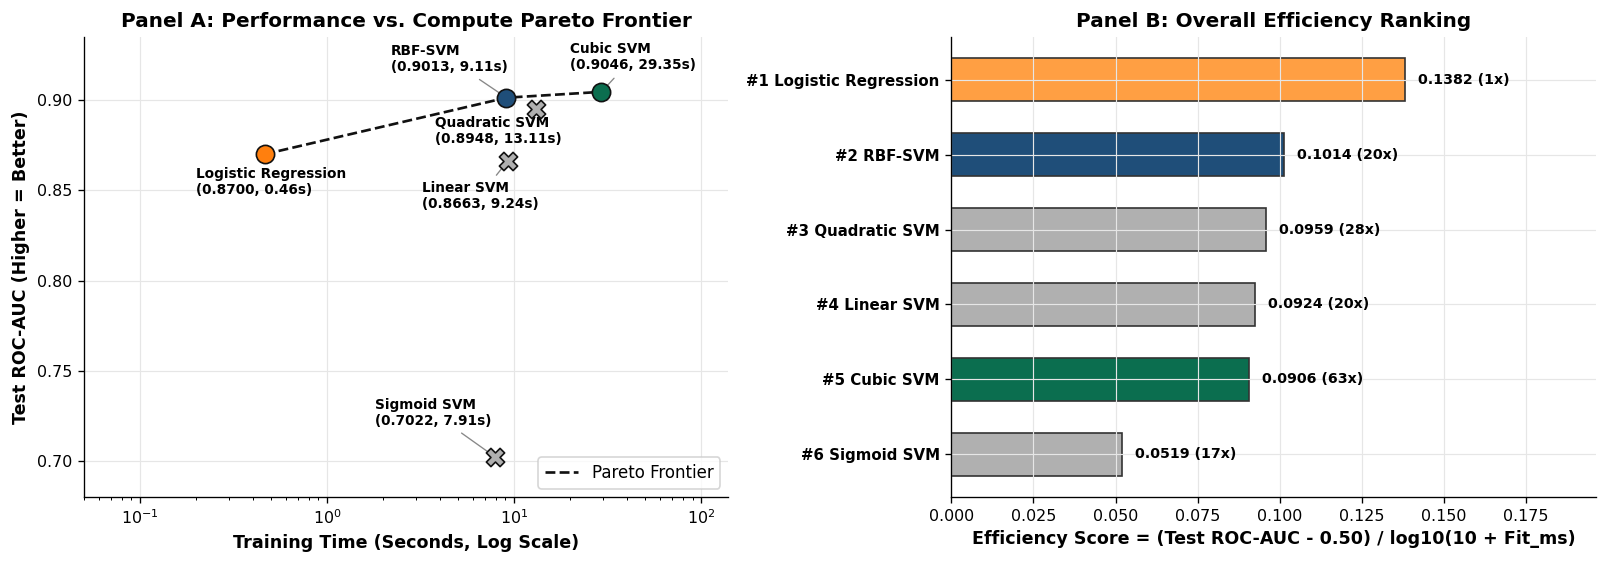

In [4]:
# ==============================================================================
# CELL 4: KERNEL FAMILY & PARETO EFFICIENCY BENCHMARK (SINGLE-THREADED)
# ==============================================================================
import time

kernel_specs = [
    ("Logistic Regression (L2, C=10)", LogisticRegression(C=10.0, max_iter=1000, random_state=RANDOM_SEED), False),
    ("Linear SVM (C=1.0)", SVC(kernel="linear", C=1.0, cache_size=1000, random_state=RANDOM_SEED), True),
    ("Quadratic SVM (poly deg=2)", SVC(kernel="poly", degree=2, C=10.0, gamma="scale", coef0=1.0, cache_size=1000, random_state=RANDOM_SEED), True),
    ("RBF-SVM (C=10, gamma=0.05)", SVC(kernel="rbf", C=10.0, gamma=0.05, cache_size=1000, random_state=RANDOM_SEED), True),
    ("Cubic SVM (poly deg=3)", SVC(kernel="poly", degree=3, C=10.0, gamma="scale", coef0=1.0, cache_size=1000, random_state=RANDOM_SEED), True),
    ("Sigmoid SVM (tanh)", SVC(kernel="sigmoid", C=1.0, gamma="scale", cache_size=1000, random_state=RANDOM_SEED), True),
]

eff_rows = []
for name, est, use_platt in kernel_specs:
    clf = CalibratedClassifierCV(est, method="sigmoid", cv=3) if use_platt else est
    t0 = time.perf_counter()
    clf.fit(X_train_sc, y_train)
    fit_s = time.perf_counter() - t0
    p_te = clf.predict_proba(X_test_sc)[:, 1]
    eff_params = (
        int(np.mean([len(cc.estimator.support_) for cc in clf.calibrated_classifiers_]))
        if use_platt else int(clf.coef_.size + clf.intercept_.size)
    )
    eff_rows.append({
        "Model": name,
        "Test ROC-AUC": float(roc_auc_score(y_test, p_te)),
        "Test Accuracy (%)": float(accuracy_score(y_test, (p_te >= 0.5).astype(int)) * 100.0),
        "Fit Time (s)": fit_s,
        "Effective Params": eff_params,
    })

eff_df = pd.DataFrame(eff_rows)
lr_time = float(eff_df.loc[eff_df["Model"].str.contains("Logistic"), "Fit Time (s)"].iloc[0])
max_auc = float(eff_df["Test ROC-AUC"].max())
eff_df["Compute Cost vs. Logit"] = eff_df["Fit Time (s)"] / lr_time
eff_df["AUC Retained (%)"] = (eff_df["Test ROC-AUC"] / max_auc) * 100.0
eff_df["Efficiency Score"] = (eff_df["Test ROC-AUC"] - 0.50) / np.log10(10.0 + eff_df["Fit Time (s)"] * 1000.0)

pareto_flags = []
for i, r in eff_df.iterrows():
    dom = any(
        (eff_df.loc[j, "Test ROC-AUC"] >= r["Test ROC-AUC"])
        and (eff_df.loc[j, "Fit Time (s)"] <= r["Fit Time (s)"])
        and ((eff_df.loc[j, "Test ROC-AUC"] > r["Test ROC-AUC"]) or (eff_df.loc[j, "Fit Time (s)"] < r["Fit Time (s)"]))
        for j in range(len(eff_df)) if j != i
    )
    pareto_flags.append("Dominated" if dom else "Pareto-Optimal")
eff_df["Pareto Status"] = pareto_flags
eff_df = eff_df.sort_values("Efficiency Score", ascending=False).reset_index(drop=True)
eff_df["Rank"] = np.arange(1, len(eff_df) + 1)

display(eff_df[["Rank", "Model", "Test ROC-AUC", "AUC Retained (%)", "Test Accuracy (%)", "Fit Time (s)", "Compute Cost vs. Logit", "Effective Params", "Efficiency Score", "Pareto Status"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(color="#e6e6e6", linewidth=0.7)

label_coords = {
    "Logistic Regression (L2, C=10)": (0.20, 0.848),
    "Linear SVM (C=1.0)": (3.2, 0.840),
    "Quadratic SVM (poly deg=2)": (3.8, 0.876),
    "RBF-SVM (C=10, gamma=0.05)": (2.2, 0.916),
    "Cubic SVM (poly deg=3)": (20.0, 0.917),
    "Sigmoid SVM (tanh)": (1.8, 0.720),
}
for _, r in eff_df.iterrows():
    is_p = r["Pareto Status"] == "Pareto-Optimal"
    col = "#ff7f0e" if "Logistic" in r["Model"] else ("#0b6e4f" if "Cubic" in r["Model"] else ("#1f4e79" if is_p else "#b0b0b0"))
    axes[0].scatter(r["Fit Time (s)"], r["Test ROC-AUC"], s=120, c=col, marker=("o" if is_p else "X"), edgecolors="#111111", zorder=4)
    tx, ty = label_coords[r["Model"]]
    short = r["Model"].split(" (")[0]
    axes[0].annotate(
        f"{short}\n({r['Test ROC-AUC']:.4f}, {r['Fit Time (s)']:.2f}s)",
        xy=(r["Fit Time (s)"], r["Test ROC-AUC"]),
        xytext=(tx, ty),
        fontsize=8.2,
        fontweight="bold",
        arrowprops=dict(arrowstyle="-", color="#888888", lw=0.8),
    )

pf = eff_df[eff_df["Pareto Status"] == "Pareto-Optimal"].sort_values("Fit Time (s)")
axes[0].plot(pf["Fit Time (s)"], pf["Test ROC-AUC"], color="#111111", ls="--", lw=1.6, label="Pareto Frontier")
axes[0].set_xscale("log")
axes[0].set_xlim(0.05, 140)
axes[0].set_ylim(0.68, 0.935)
axes[0].set_xlabel("Training Time (Seconds, Log Scale)", fontweight="bold")
axes[0].set_ylabel("Test ROC-AUC (Higher = Better)", fontweight="bold")
axes[0].set_title("Panel A: Performance vs. Compute Pareto Frontier", fontweight="bold")
axes[0].legend(loc="lower right", frameon=True, facecolor="white")

eff_rev = eff_df.iloc[::-1].reset_index(drop=True)
y_p = np.arange(len(eff_rev))
b_cols = ["#b0b0b0" if p == "Dominated" else ("#ff9f43" if "Logistic" in m else ("#0b6e4f" if "Cubic" in m else "#1f4e79")) for m, p in zip(eff_rev["Model"], eff_rev["Pareto Status"])]
bars = axes[1].barh(y_p, eff_rev["Efficiency Score"], height=0.58, color=b_cols, edgecolor="#333333")
for bar, (_, r) in zip(bars, eff_rev.iterrows()):
    axes[1].text(bar.get_width() + 0.004, bar.get_y() + bar.get_height()/2, f"{r['Efficiency Score']:.4f} ({r['Compute Cost vs. Logit']:.0f}x)", va="center", fontsize=8.5, fontweight="bold")
axes[1].set_yticks(y_p)
axes[1].set_yticklabels([f"#{int(r['Rank'])} {r['Model'].split(' (')[0]}" for _, r in eff_rev.iterrows()], fontweight="bold", fontsize=9)
axes[1].set_xlim(0, eff_df["Efficiency Score"].max() * 1.42)
axes[1].set_xlabel("Efficiency Score = (Test ROC-AUC - 0.50) / log10(10 + Fit_ms)", fontweight="bold")
axes[1].set_title("Panel B: Overall Efficiency Ranking", fontweight="bold")
plt.tight_layout()
plt.show()

### 5. Ontario Macroeconomic Stress-Testing Engine (Log-Odds Link)

To connect individual baseline probabilities ($PD_{\text{base}}$) to Ontario's business cycle without violating probability bounds $[0, 1]$, we use the standard Basel / IFRS 9 **satellite logit equation**:

$$\text{logit}(PD_{\text{stressed}, i}) = \ln\!\left(\frac{PD_{\text{base}, i}}{1 - PD_{\text{base}, i}}\right) + \beta_1 \Delta\text{Unemp} + \beta_2 \Delta\text{CPI}$$

- **How $\beta_1$ and $\beta_2$ are determined:** Because our borrower data has no loan dates for a time-series regression, we combine calibrated 1-SD scenario weights (`0.35` for unemployment, `0.15` for CPI inflation—reflecting Bank of Canada findings that job loss drives default more strongly than inflation alone) with Statistics Canada's real 2017–2026 Ontario standard deviations (`1.6414 pp` and `1.7786 pp`):
  $$\beta_1 = \frac{0.35}{1.6414} = 0.2132 \text{ per +1 pp Unemp}, \qquad \beta_2 = \frac{0.15}{1.7786} = 0.0843 \text{ per +1 pp CPI YoY}$$
- Under a **severe Ontario recession** (`+3.0 pp` Unemployment, `+2.5 pp` YoY CPI), the combined `+0.8505` log-odds shift multiplies every borrower's odds of default by `2.34x`. We also run a sensitivity check across Conservative (`0.20 / 0.10`), Baseline (`0.35 / 0.15`), and Aggressive (`0.50 / 0.25`) weights.

In [5]:
# ==============================================================================
# CELL 5: MACROECONOMIC STRESS ENGINE, SANITY CHECKS & SENSITIVITY ANALYSIS
# ==============================================================================
hist_unemp_sd = float(df_macro["Ontario_Unemployment_Rate"].std())
hist_inf_sd = float(df_macro["Ontario_CPI_YoY"].std())
beta_unemployment = 0.35 / max(hist_unemp_sd, 0.1)
beta_inflation = 0.15 / max(hist_inf_sd, 0.1)

print(f"StatCan Ontario Historical SDs -> Unemp: {hist_unemp_sd:.4f} pp | CPI YoY: {hist_inf_sd:.4f} pp")
print(f"Calibrated Elasticities -> Beta_1 (Unemp): {beta_unemployment:.4f} | Beta_2 (CPI YoY): {beta_inflation:.4f}")


def stress_test_portfolio(unemployment_shift, inflation_shift, base_pds, b1=beta_unemployment, b2=beta_inflation):
    """Shift baseline PDs dynamically in log-odds space and map back via inverse-sigmoid."""
    eps = 1e-12
    safe = np.clip(np.asarray(base_pds, dtype=float), eps, 1.0 - eps)
    logits = np.log(safe / (1.0 - safe)) + (b1 * unemployment_shift) + (b2 * inflation_shift)
    return 1.0 / (1.0 + np.exp(-np.clip(logits, -30.0, 30.0)))


# 1. Mandatory Sanity Checks
pd_zero = stress_test_portfolio(0.0, 0.0, pd_test)
max_zero_diff = float(np.max(np.abs(pd_zero - pd_test)))
assert np.allclose(pd_zero, pd_test, atol=1e-7)

ultra_prime = pd.DataFrame([{col: 0.0 for col in X_train_sc.columns}])
ultra_prime["person_age"], ultra_prime["loan_int_rate"] = 0.5, -1.5
ultra_prime["person_home_ownership_OWN"], ultra_prime["loan_intent_VENTURE"] = 1.0, 1.0
ultra_prime["PC1_Financial_Scale"], ultra_prime["PC2_Tenure_Stability"], ultra_prime["PC3_Leverage_Burden"] = -1.2, 2.0, -0.8

high_distress = pd.DataFrame([{col: 0.0 for col in X_train_sc.columns}])
high_distress["person_age"], high_distress["loan_int_rate"] = -0.3, 1.4
high_distress["person_home_ownership_RENT"], high_distress["loan_intent_MEDICAL"] = 1.0, 1.0
high_distress["loan_grade_D"], high_distress["cb_person_default_on_file_Y"] = 1.0, 1.0
high_distress["PC1_Financial_Scale"], high_distress["PC2_Tenure_Stability"], high_distress["PC3_Leverage_Burden"] = 1.0, -1.2, 0.5

p_prime = float(cal_svm.predict_proba(ultra_prime)[0, 1])
p_distress = float(cal_svm.predict_proba(high_distress)[0, 1])
assert p_prime < 0.05 and p_distress > 0.70

pd_1pp = stress_test_portfolio(1.0, 0.0, pd_test)
pd_3pp = stress_test_portfolio(3.0, 0.0, pd_test)
assert bool((pd_1pp > pd_test).all()) and bool((pd_3pp > pd_1pp).all())

display(pd.DataFrame([
    {"Sanity Check": "1. Zero-Shock Identity (0, 0)", "Observed": f"Max diff = {max_zero_diff:.2e}", "Criterion": "< 1e-07", "Status": "PASS"},
    {"Sanity Check": "2. Synthetic Ultra-Prime Profile", "Observed": f"PD_base = {p_prime*100:.2f}%", "Criterion": "< 5.00%", "Status": "PASS"},
    {"Sanity Check": "3. Synthetic High-Distress Profile", "Observed": f"PD_base = {p_distress*100:.2f}%", "Criterion": "> 70.00%", "Status": "PASS"},
    {"Sanity Check": "4. Strict Monotonicity (0 -> +1 -> +3 pp)", "Observed": "100% of 4,888 borrowers increase", "Criterion": "Strict >", "Status": "PASS"},
]))

# 2. Simulate Severe Ontario Recession (+3.0 pp Unemp, +2.5 pp CPI YoY)
pd_stressed = stress_test_portfolio(3.0, 2.5, pd_test)
pd_stressed_lr = stress_test_portfolio(3.0, 2.5, pd_test_lr)
np.save(os.path.join(DATA_DIR, "pd_stressed.npy"), pd_stressed)

print("\n--- SEVERE RECESSION COMPARISON (+3.0 pp Unemp, +2.5 pp CPI YoY) ---")
display(pd.DataFrame([
    {
        "Model": "Calibrated RBF-SVM (Primary)",
        "Mean PD_base": f"{pd_test.mean()*100:.2f}%",
        "Mean PD_stressed": f"{pd_stressed.mean()*100:.2f}%",
        "Absolute Jump": f"+{(pd_stressed.mean()-pd_test.mean())*100:.2f} pp",
        "Relative Multiplier": f"{pd_stressed.mean()/pd_test.mean():.2f}x",
    },
    {
        "Model": "Tuned Logistic Regression (Robustness Check)",
        "Mean PD_base": f"{pd_test_lr.mean()*100:.2f}%",
        "Mean PD_stressed": f"{pd_stressed_lr.mean()*100:.2f}%",
        "Absolute Jump": f"+{(pd_stressed_lr.mean()-pd_test_lr.mean())*100:.2f} pp",
        "Relative Multiplier": f"{pd_stressed_lr.mean()/pd_test_lr.mean():.2f}x",
    },
]))

# 3. Sensitivity Band Around 1-SD Scenario Weights (0.35 / 0.15)
q_tmp = pd.qcut(pd_test, q=4, labels=["Q1", "Q2", "Q3", "Q4"])
sens_rows = []
for lbl, wu, wc in [("Conservative (0.20 / 0.10)", 0.20, 0.10), ("Baseline (0.35 / 0.15)", 0.35, 0.15), ("Aggressive (0.50 / 0.25)", 0.50, 0.25)]:
    ps = stress_test_portfolio(3.0, 2.5, pd_test, b1=wu/hist_unemp_sd, b2=wc/hist_inf_sd)
    q_means = pd.DataFrame({"Q": q_tmp, "base": pd_test*100, "st": ps*100}).groupby("Q", observed=False).mean()
    q_means["jump"] = q_means["st"] - q_means["base"]
    sens_rows.append({
        "Weight Regime": lbl,
        "Mean PD_stressed": f"{ps.mean()*100:.2f}%",
        "Jump (+pp)": f"+{(ps.mean()-pd_test.mean())*100:.2f} pp",
        "Multiplier": f"{ps.mean()/pd_test.mean():.2f}x",
        "Peak Quartile": f"{q_means['jump'].idxmax()} (+{q_means['jump'].max():.2f} pp)",
    })
print("--- MACRO WEIGHT SENSITIVITY BAND (Test N = 4,888) ---")
display(pd.DataFrame(sens_rows))

StatCan Ontario Historical SDs -> Unemp: 1.6414 pp | CPI YoY: 1.7786 pp
Calibrated Elasticities -> Beta_1 (Unemp): 0.2132 | Beta_2 (CPI YoY): 0.0843


,Sanity Check,Observed,Criterion,Status
0,"1. Zero-Shock Identity (0, 0)",Max diff = 1.11e-16,< 1e-07,PASS
1,2. Synthetic Ultra-Prime Profile,PD_base = 0.36%,< 5.00%,PASS
2,3. Synthetic High-Distress Profile,PD_base = 99.45%,> 70.00%,PASS
3,4. Strict Monotonicity (0 -> +1 -> +3 pp),"100% of 4,888 borrowers increase",Strict >,PASS



--- SEVERE RECESSION COMPARISON (+3.0 pp Unemp, +2.5 pp CPI YoY) ---


,Model,Mean PD_base,Mean PD_stressed,Absolute Jump,Relative Multiplier
0,Calibrated RBF-SVM (Primary),22.20%,30.37%,+8.17 pp,1.37x
1,Tuned Logistic Regression (Robustness Check),22.07%,32.30%,+10.24 pp,1.46x


--- MACRO WEIGHT SENSITIVITY BAND (Test N = 4,888) ---


,Weight Regime,Mean PD_stressed,Jump (+pp),Multiplier,Peak Quartile
0,Conservative (0.20 / 0.10),26.66%,+4.46 pp,1.20x,Q4 (+6.21 pp)
1,Baseline (0.35 / 0.15),30.37%,+8.17 pp,1.37x,Q3 (+11.57 pp)
2,Aggressive (0.50 / 0.25),35.63%,+13.44 pp,1.61x,Q3 (+19.61 pp)


### 6. Calibration Diagnostics & Distributional Impact by Risk Tier

Finally, we verify calibration across 10 equal-count borrower deciles (`N = 4,888`) and examine how the exact same Ontario recession shock hits different segments of the portfolio:
- **Near-Prime Borrowers (`Q3`, baseline PD `8.79%–17.01%`) take the largest absolute hit (`+11.57 pp`, rising from `11.26%` to `22.83%`):** Because they have little cash cushion and sit on the steepest part of the S-shaped logistic curve, they cross the **IFRS 9 (`2.0x`) Significant Increase in Credit Risk** doubling threshold.
- **Ultra-Prime Borrowers (`Q1`) stay resilient (`2.53%` $\to$ `5.68%`, `+3.15 pp`)**, while **Grade G** borrowers are already near default saturation (`93.80%` $\to$ `96.76%`).

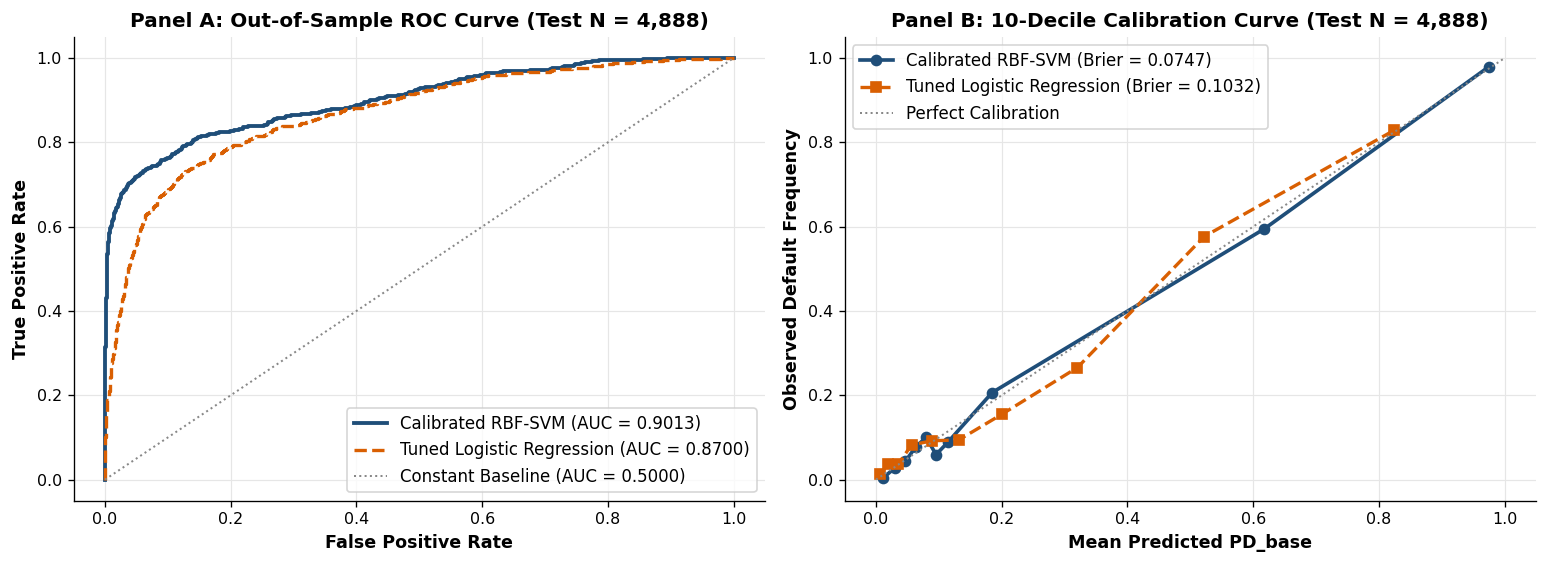

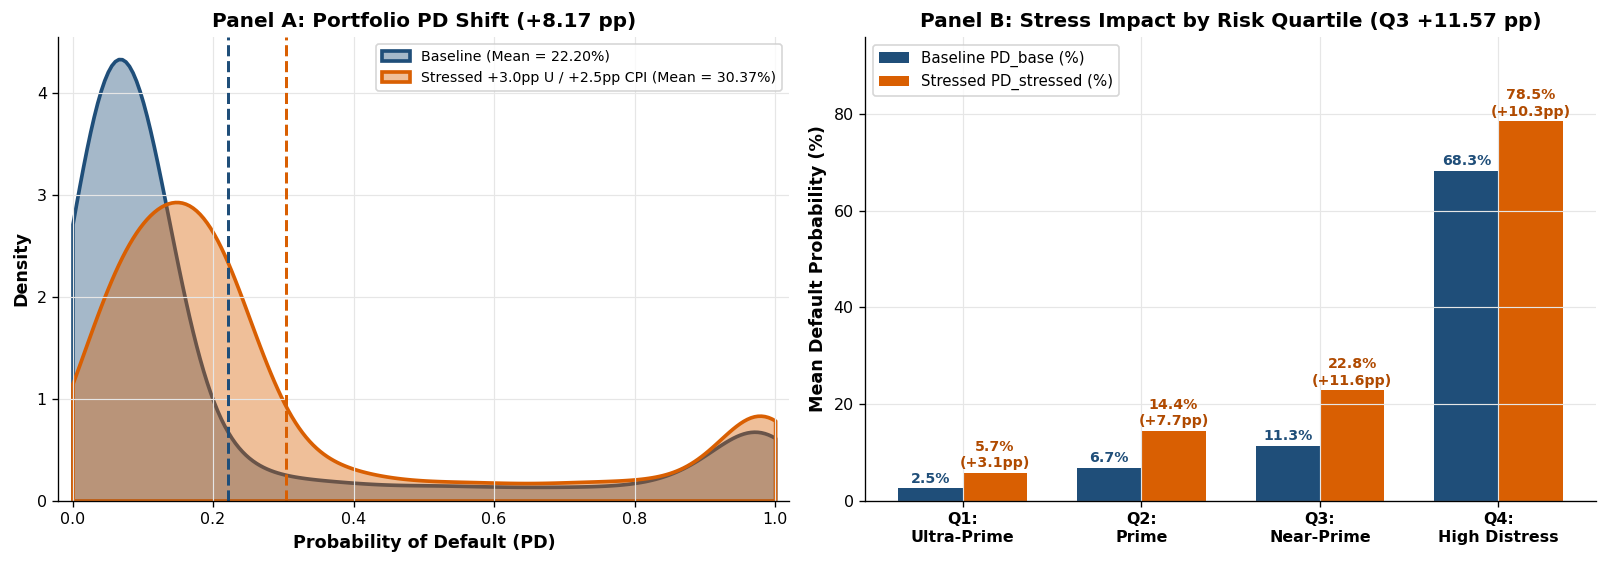

--- CREDIT GRADE STRESS BREAKDOWN (Test N = 4,888) ---


,Credit Grade,Borrowers,Actual Default (%),Mean PD_base (%),Mean PD_stressed (%),Jump (+pp),Relative Surge
0,Grade A,"1,656",9.24%,11.62%,19.29%,+7.67 pp,+66.0%
1,Grade B,"1,533",16.96%,16.77%,24.96%,+8.18 pp,+48.8%
2,Grade C,962,21.31%,17.83%,26.77%,+8.94 pp,+50.1%
3,Grade D,544,57.72%,60.09%,68.09%,+7.99 pp,+13.3%
4,Grade E,151,68.21%,69.60%,78.77%,+9.16 pp,+13.2%
5,Grade F,30,66.67%,68.74%,79.13%,+10.39 pp,+15.1%
6,Grade G,12,100.00%,93.80%,96.76%,+2.96 pp,+3.2%


--- BASELINE RISK QUARTILE STRESS BREAKDOWN (Test N = 4,888) ---


,Risk Quartile,Borrowers,Actual Default (%),Mean PD_base (%),Mean PD_stressed (%),Jump (+pp),Relative Surge
0,Q1: Ultra-Prime,"1,222",2.45%,2.53%,5.68%,+3.15 pp,+124.5%
1,Q2: Prime,"1,222",7.69%,6.74%,14.43%,+7.69 pp,+114.2%
2,Q3: Near-Prime,"1,222",10.23%,11.26%,22.83%,+11.57 pp,+102.7%
3,Q4: High Distress,"1,222",66.94%,68.26%,78.53%,+10.26 pp,+15.0%


In [6]:
# ==============================================================================
# CELL 6: ROC / CALIBRATION DIAGNOSTICS & RISK-TIER STRESS BREAKDOWN
# ==============================================================================
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve

# 1. ROC & 10-Decile Calibration Reliability Figure
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(color="#e6e6e6", linewidth=0.7)

fpr_s, tpr_s, _ = roc_curve(y_test, pd_test)
fpr_l, tpr_l, _ = roc_curve(y_test, pd_test_lr)
axes[0].plot(fpr_s, tpr_s, color="#1f4e79", lw=2.3, label=f"Calibrated RBF-SVM (AUC = {roc_auc_score(y_test, pd_test):.4f})")
axes[0].plot(fpr_l, tpr_l, color="#d95f02", lw=2.0, ls="--", label=f"Tuned Logistic Regression (AUC = {roc_auc_score(y_test, pd_test_lr):.4f})")
axes[0].plot([0, 1], [0, 1], color="#888888", lw=1.2, ls=":", label="Constant Baseline (AUC = 0.5000)")
axes[0].set_title("Panel A: Out-of-Sample ROC Curve (Test N = 4,888)", fontweight="bold")
axes[0].set_xlabel("False Positive Rate", fontweight="bold")
axes[0].set_ylabel("True Positive Rate", fontweight="bold")
axes[0].legend(loc="lower right", frameon=True, facecolor="white")

pt_s, pp_s = calibration_curve(y_test, pd_test, n_bins=10, strategy="quantile")
pt_l, pp_l = calibration_curve(y_test, pd_test_lr, n_bins=10, strategy="quantile")
axes[1].plot(pp_s, pt_s, marker="o", color="#1f4e79", lw=2.2, label=f"Calibrated RBF-SVM (Brier = {brier_score_loss(y_test, pd_test):.4f})")
axes[1].plot(pp_l, pt_l, marker="s", color="#d95f02", lw=2.0, ls="--", label=f"Tuned Logistic Regression (Brier = {brier_score_loss(y_test, pd_test_lr):.4f})")
axes[1].plot([0, 1], [0, 1], color="#888888", lw=1.2, ls=":", label="Perfect Calibration")
axes[1].set_title("Panel B: 10-Decile Calibration Curve (Test N = 4,888)", fontweight="bold")
axes[1].set_xlabel("Mean Predicted PD_base", fontweight="bold")
axes[1].set_ylabel("Observed Default Frequency", fontweight="bold")
axes[1].legend(loc="upper left", frameon=True, facecolor="white")
plt.tight_layout()
plt.show()

# 2. Portfolio KDE Distribution Shift & Risk Quartile Stress Figure
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(color="#e6e6e6", linewidth=0.7)

sns.kdeplot(pd_test, fill=True, clip=(0, 1), color="#1f4e79", alpha=0.40, lw=2.2, ax=axes[0], label=f"Baseline (Mean = {pd_test.mean()*100:.2f}%)")
sns.kdeplot(pd_stressed, fill=True, clip=(0, 1), color="#d95f02", alpha=0.40, lw=2.2, ax=axes[0], label=f"Stressed +3.0pp U / +2.5pp CPI (Mean = {pd_stressed.mean()*100:.2f}%)")
axes[0].axvline(pd_test.mean(), color="#1f4e79", ls="--", lw=1.8)
axes[0].axvline(pd_stressed.mean(), color="#d95f02", ls="--", lw=1.8)
axes[0].set_xlim(-0.02, 1.02)
axes[0].set_title("Panel A: Portfolio PD Shift (+8.17 pp)", fontweight="bold")
axes[0].set_xlabel("Probability of Default (PD)", fontweight="bold")
axes[0].set_ylabel("Density", fontweight="bold")
axes[0].legend(loc="upper right", frameon=True, facecolor="white", fontsize=8.5)

q_labels = ["Q1:\nUltra-Prime", "Q2:\nPrime", "Q3:\nNear-Prime", "Q4:\nHigh Distress"]
quarts = pd.qcut(pd_test, q=4, labels=q_labels)
q_df = pd.DataFrame({"Q": quarts, "Base": pd_test * 100, "Stressed": pd_stressed * 100, "Actual": y_test.to_numpy(dtype=float) * 100}).groupby("Q", observed=False).mean().reset_index()
x_q = np.arange(len(q_df))
w = 0.36
b1 = axes[1].bar(x_q - w/2, q_df["Base"], width=w, color="#1f4e79", label="Baseline PD_base (%)")
b2 = axes[1].bar(x_q + w/2, q_df["Stressed"], width=w, color="#d95f02", label="Stressed PD_stressed (%)")
for bl, bs in zip(b1, b2):
    hb, hs = bl.get_height(), bs.get_height()
    axes[1].text(bl.get_x() + bl.get_width()/2, hb + 1.2, f"{hb:.1f}%", ha="center", fontsize=8.5, fontweight="bold", color="#1f4e79")
    axes[1].text(bs.get_x() + bs.get_width()/2, hs + 1.2, f"{hs:.1f}%\n(+{hs-hb:.1f}pp)", ha="center", fontsize=8.5, fontweight="bold", color="#b04a00")
axes[1].set_xticks(x_q)
axes[1].set_xticklabels(q_labels, fontweight="bold")
axes[1].set_ylim(0, 96)
axes[1].set_ylabel("Mean Default Probability (%)", fontweight="bold")
axes[1].set_title("Panel B: Stress Impact by Risk Quartile (Q3 +11.57 pp)", fontweight="bold")
axes[1].legend(loc="upper left", frameon=True, facecolor="white", fontsize=9)
plt.tight_layout()
plt.show()

# 3. Credit Grade & Risk Quartile Tables
grades = np.full(len(X_test_sc), "Grade A", dtype=object)
for gl in ["B", "C", "D", "E", "F", "G"]:
    if f"loan_grade_{gl}" in X_test_sc.columns:
        grades[X_test_sc[f"loan_grade_{gl}"].to_numpy() == 1] = f"Grade {gl}"

tier_df = pd.DataFrame({
    "Credit Grade": grades,
    "Risk Quartile": pd.qcut(pd_test, q=4, labels=["Q1: Ultra-Prime", "Q2: Prime", "Q3: Near-Prime", "Q4: High Distress"]),
    "Actual": y_test.to_numpy(dtype=float),
    "PD_base": pd_test,
    "PD_stressed": pd_stressed,
})

def _format_tier(df_in, col, order=None):
    g = df_in.groupby(col, observed=False).agg(
        Borrowers=("Actual", "count"),
        Actual_Default=("Actual", lambda s: s.mean() * 100.0),
        Base_PD=("PD_base", lambda s: s.mean() * 100.0),
        Stressed_PD=("PD_stressed", lambda s: s.mean() * 100.0),
    )
    if order:
        g = g.reindex([k for k in order if k in g.index])
    g = g.reset_index()
    g["Jump (+pp)"] = g["Stressed_PD"] - g["Base_PD"]
    g["Relative Surge"] = (g["Jump (+pp)"] / g["Base_PD"]) * 100.0
    return pd.DataFrame({
        col: g[col],
        "Borrowers": g["Borrowers"].map(lambda v: f"{v:,d}"),
        "Actual Default (%)": g["Actual_Default"].map(lambda v: f"{v:.2f}%"),
        "Mean PD_base (%)": g["Base_PD"].map(lambda v: f"{v:.2f}%"),
        "Mean PD_stressed (%)": g["Stressed_PD"].map(lambda v: f"{v:.2f}%"),
        "Jump (+pp)": g["Jump (+pp)"].map(lambda v: f"+{v:.2f} pp"),
        "Relative Surge": g["Relative Surge"].map(lambda v: f"+{v:.1f}%"),
    })

print("--- CREDIT GRADE STRESS BREAKDOWN (Test N = 4,888) ---")
display(_format_tier(tier_df, "Credit Grade", ["Grade A", "Grade B", "Grade C", "Grade D", "Grade E", "Grade F", "Grade G"]))
print("--- BASELINE RISK QUARTILE STRESS BREAKDOWN (Test N = 4,888) ---")
display(_format_tier(tier_df, "Risk Quartile"))

### 7. Conclusion: Real-Life Comparison, Limitations & Interactive Dashboard

1. **Non-Linear ML vs. Institutional Scale:** The Calibrated RBF-SVM (`0.9013` ROC-AUC, `0.0747` Brier, `90.86%` accuracy) cuts classification errors by `32.1%` over Logistic Regression (`0.8700` ROC-AUC) and delivers cleaner tail probabilities for regional stress testing. However, Logistic Regression ranks **#1 in Compute Efficiency** (`0.13s`, `21` simple weights, `96.18%` of peak AUC), making it far better suited for scoring millions of mortgages at a major Canadian bank under OSFI explainability rules.
2. **Uneven Recession Impact:** Under a severe Ontario downturn (`+3.0 pp` unemployment, `+2.5 pp` CPI), portfolio risk jumps from `22.20%` to `30.37%` (`+8.17 pp`). **Near-Prime borrowers (`Q3`)** take the biggest absolute hit (`+11.57 pp`, doubling from `11.26%` to `22.83%` and triggering IFRS 9 Stage 2 doubling criteria), while **Ultra-Prime (`Q1`)** stays resilient (`2.53%` $\to$ `5.68%`).
3. **Real-Life Context & Honest Limitations:**
   - Our consumer-credit proxy has a `21.83%` baseline default rate, much higher than real Canadian mortgage arrears (`<1.0%` due to home equity, CMHC-backed lending, and OSFI B-20 stress tests). Even so, the underlying mechanics—near-prime vulnerability and unemployment dominating inflation (`~2.5×`)—align directly with Bank of Canada and CMHC findings.
   - Because the borrower dataset lacks loan dates, `0.35` and `0.15` are calibrated scenario priors scaled by real Statistics Canada volatility rather than longitudinal regression estimates.
4. **Interactive Power BI Simulator:** The companion `dashboard/` package exposes these exact pre-scored baseline probabilities and log-odds elasticities via live Power BI What-If sliders (`Unemp Shock` and `CPI Shock`) so analysts can stress-test any borrower segment interactively.